# Complete log-likelihood around the SAEM estimates

This notebook tests `score_visualizer.py` on a simple model.

For each parameter $\theta_k$ (Beta, MI, Omega, sigma², survival coefficients), its value is moved around the SAEM estimate $\hat\theta_k$ while the other parameters stay fixed, and we plot the complete log-likelihood averaged over the conditional samples:

$$
\sum_{i=1}^N \frac1M\sum_{m=1}^M \log p\big(y_i, \phi_i^{(m)} ; \theta_k\big).
$$

We then check whether the log-likelihood has reached a local maximum.

In [248]:
import numpy as np
import pandas as pd
import torch

from vpop_calibration.api import (
    Config,
    NlmeConfigDict,
    NlmeModel,
    SaemConfigDict,
    StructuralAnalytical,
)
from vpop_calibration.pynlme.score_visualizer import (
    compute_log_likelihood_around_estimates,
    get_displayed_estimates,
    plot_log_likelihood_around_estimates,
    plot_normalized_scores,
)

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Model and simulated data

Two individual parameters $x_{1,i}$ and $x_{2,i}$, log-normal and **correlated** (with a covariate effect $c_i$ on $x_1$), a common slope (MI) and an additive error on each of the two outputs:

$$
\begin{pmatrix}\log x_{1,i}\\ \log x_{2,i}\end{pmatrix} =
\begin{pmatrix}\beta_1 + \beta_c\, c_i\\ \beta_2\end{pmatrix} + \eta_i,\qquad
\eta_i \sim \mathcal N\!\left(0,\ \begin{pmatrix}\omega_1^2 & \rho\,\omega_1\omega_2\\ \rho\,\omega_1\omega_2 & \omega_2^2\end{pmatrix}\right),
$$

$$
y_{1,ij} = \log x_{1,i} + \text{slope}\cdot t_j + \varepsilon_{1,ij},\qquad
y_{2,ij} = \log x_{2,i} + \text{slope}\cdot t_j + \varepsilon_{2,ij},\qquad
\varepsilon_{k,ij} \sim \mathcal N(0, \sigma_k^2).
$$

In [249]:
def noiseless_observations(x_1, x_2, slope, t):
    return torch.cat(
        (torch.log(x_1) + slope * t, torch.log(x_2) + slope * t), dim=-1
    )


struct_model = StructuralAnalytical(noiseless_observations, ["y_1", "y_2"])

NB_PATIENTS = 100
TIMES = np.arange(5, dtype=float)
TRUE_VALUES = {
    "x_1": 42,
    "covariate_effect_x_1": 0.3,
    "x_2": 0.01,
    "omega_x_1": 0.4,
    "omega_x_2": 0.3,
    "corr_x_2_x_1": 0.9,
    "slope": 0.5,
    "sd_add_y_1": 0.2,
    "sd_add_y_2": 0.2,
}

rng = np.random.default_rng(2026)
ids = [f"patient_{i:03d}" for i in range(NB_PATIENTS)]
covariate = rng.normal(0.0, 1.0, NB_PATIENTS)

omega_1, omega_2, rho = (
    TRUE_VALUES["omega_x_1"],
    TRUE_VALUES["omega_x_2"],
    TRUE_VALUES["corr_x_2_x_1"],
)
covariance_matrix = np.array(
    [[omega_1**2, rho * omega_1 * omega_2], [rho * omega_1 * omega_2, omega_2**2]]
)
etas = rng.multivariate_normal(np.zeros(2), covariance_matrix, NB_PATIENTS)

log_x_1 = (
    np.log(TRUE_VALUES["x_1"])
    + TRUE_VALUES["covariate_effect_x_1"] * covariate
    + etas[:, 0]
)
log_x_2 = np.log(TRUE_VALUES["x_2"]) + etas[:, 1]

rows = []
for output, log_x, sd in [
    ("y_1", log_x_1, TRUE_VALUES["sd_add_y_1"]),
    ("y_2", log_x_2, TRUE_VALUES["sd_add_y_2"]),
]:
    values = (
        log_x[:, None]
        + TRUE_VALUES["slope"] * TIMES[None, :]
        + rng.normal(0.0, sd, (NB_PATIENTS, len(TIMES)))
    )
    rows.append(
        pd.DataFrame(
            {
                "id": np.repeat(ids, len(TIMES)),
                "time": np.tile(TIMES, NB_PATIENTS),
                "protocol_arm": "identity",
                "output_name": output,
                "value": values.ravel(),
                "c": np.repeat(covariate, len(TIMES)),
            }
        )
    )
observations_dataframe = pd.concat(rows, ignore_index=True)
observations_dataframe.head()

,id,time,protocol_arm,output_name,value,c
0,patient_000,0.0,identity,y_1,4.283521,-0.793122
1,patient_000,1.0,identity,y_1,4.566810,-0.793122
2,patient_000,2.0,identity,y_1,5.491487,-0.793122
3,patient_000,3.0,identity,y_1,6.095111,-0.793122
4,patient_000,4.0,identity,y_1,6.287514,-0.793122


## SAEM calibration

Play with the `nb_iter_learning` parameter to give the model more or less time to converge. You will see how this affects the log-likelihood around the equilibrium found.

In [250]:
model_params = {
    "pdu": {
        "x_1": {
            "prior": 0.042,
            "prior_omega": 43,
            "covariates": {"c": {"coef_name": "covariate_effect_x_1", "prior": 0.0}},
        },
        "x_2": {"prior": 0.042, "prior_omega": 43},
    },
    "model_intrinsic": {"slope": {"prior": 4.4}},
    "error_model": {
        "y_1": {"error_type": "additive", "initial_variance": 45},
        "y_2": {"error_type": "additive", "initial_variance": 45},
    },
}

config = Config(
    seed=2027,
    nlme=NlmeConfigDict(nb_chains=3, live_plot=False, progress_bar=False),
    saem=SaemConfigDict(
        nb_iter_burnin=50,
        nb_iter_learning=300,
        nb_iter_smoothing=150,
        nb_mcmc_transitions=3,
        live_plot=False,
        logging=False,
    ),
)

nlme_model = NlmeModel(
    structural_model=struct_model, df=observations_dataframe, input_params=model_params, config=config
)
nlme_model.optimizer.run()

estimates = get_displayed_estimates(nlme_model.statistical_model)
pd.DataFrame({"estimate": estimates, "truth": pd.Series(TRUE_VALUES)}).round(4)

  0%|          | 0/500 [00:00<?, ?it/s]

,estimate,truth
x_1,39.6596,42.00
covariate_effect_x_1,0.3063,0.30
x_2,0.0095,0.01
omega_x_1,0.4325,0.40
omega_x_2,0.3095,0.30
corr_x_2_x_1,0.8890,0.90
slope,0.5033,0.50
sd_add_y_1,0.2063,0.20
sd_add_y_2,0.1944,0.20


## Conditional samples

We reuse the samples of the conditional distribution $p(\phi_i \mid y_i ; \hat\Theta)$.

In [251]:
number_samples_by_patient =50
nlme_model.sample_conditional_distribution(number_samples_by_patient)

## Visualize LL around estimates with the default window (±20 %)

with a narrower window (relative_width), the bell shape is likely to be less visible.

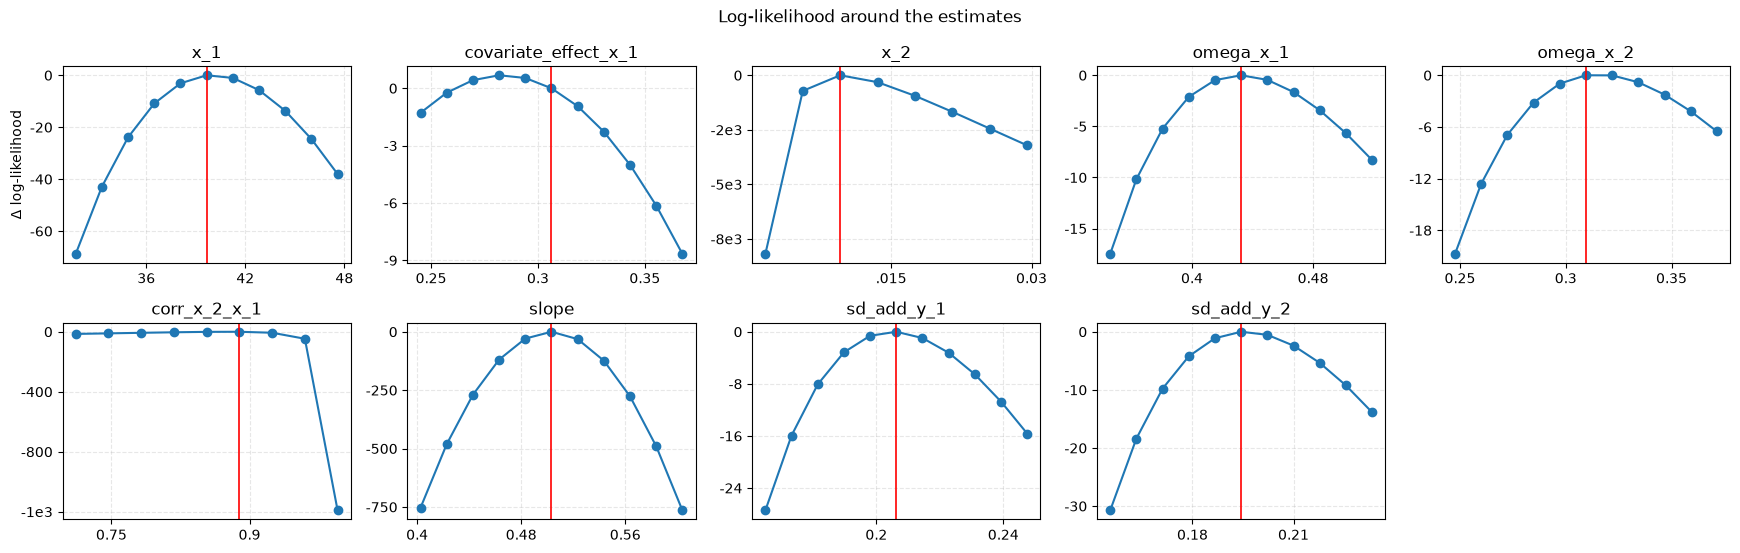

In [252]:
log_likelihood_variations = compute_log_likelihood_around_estimates(nlme_model.diagnostics, relative_width=0.2)
plot_log_likelihood_around_estimates(log_likelihood_variations)

## Visualize normalized score

which should basically be the normalized derivatives of the above curves

For each parameter $\theta_k$ and each conditional sample m, the score $g_{ik}^{(m)} = \partial_{\theta_k} \log p(y_i, \phi_i^{(m)};\hat\theta)$ is computed by finite differences. At the maximum likelihood, $\sum_i \mathbb E[g_i \mid y_i] = 0$. The estimated gradient is normalized by its noise, estimated patient by patient, and should be approximately within [-1;1] (95% within [-2, 2]) if the actual gradient g_k is "close enough" to zero:

$$
z_k = \frac{g_k}{\sqrt{\sum_i s_{ik}^2 / M}}, \qquad g_k=\sum_i \bar g_{ik},\quad \bar g_{ik} = \frac1M\sum_m g_{ik}^{(m)},\quad s_{ik}^2 = \operatorname{Var}\big(g_{ik}^{(m)}\big)\quad(=\frac{1}{M-1}\sum_{m=1}^M \big(g_{ik}^{(m)} - \bar g_{ik}\big)^2)
$$



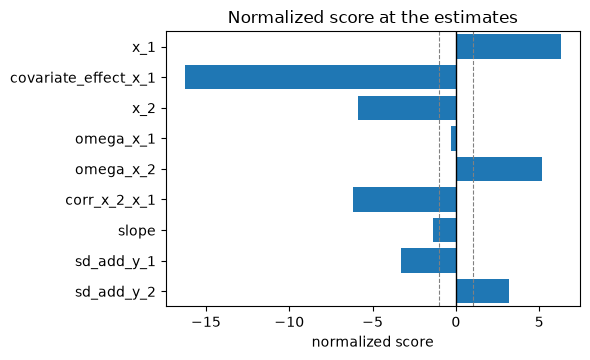

In [253]:
normalized_scores = plot_normalized_scores(nlme_model.diagnostics, bounds=(-1, 1))